# Hospital Readmission & Medication Analytics
> **Reading guide.** Steps 1-6: data understanding, cleaning and EDA. Steps 7-9: early exploratory modeling
> (compared on the test set while developing, so those numbers are superseded). **Steps 11-13 are the final,
> methodologically clean analysis**: cohort validation, cross-validated model selection, a sealed hold-out evaluated
> once, calibration, capacity analysis and a subgroup audit. README numbers come from Steps 12-13.
## Part 1: Diabetes 130-US Hospitals - Data Loading
Goal: understand which factors relate to 30-day readmission.

In [60]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Show all columns when printing tables (the dataset has 50 columns)
pd.set_option("display.max_columns", None)

# Step 2: Where the data lives (edit only this line if you move the data)
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

# Step 3: Load the data
df = pd.read_csv(DATA_DIR / "diabetic_data.csv")

# Step 4: Size and first look
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Observation: Data size
- The dataset has 101,766 rows and 50 columns.
- That is large enough for statistical analysis and ML.
- Each row is a hospital encounter (a visit), not necessarily a unique patient. We will verify this in Step 2.

## Step 2: Understanding the data

In [61]:
# Step 2.1: Column names, data types, non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [62]:
# Step 2.2: Statistical summary of numeric columns
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [63]:
# Step 2.3: Missing values are stored as "?" (pandas does not see them as NaN)
q_counts = (df == "?").sum().sort_values(ascending=False)
q_pct = (q_counts / len(df) * 100).round(1)
pd.DataFrame({"count": q_counts, "percent": q_pct})[q_counts > 0]

,count,percent
weight,98569,96.9
medical_specialty,49949,49.1
payer_code,40256,39.6
race,2273,2.2
diag_3,1423,1.4
diag_2,358,0.4
diag_1,21,0.0


### Observation: Missing values
- `weight` is 96.9% missing -> will be dropped.
- `medical_specialty` (49.1%) and `payer_code` (39.6%) are heavily missing.
  We will keep `medical_specialty` with a "Missing" category (missing may carry information)
  and drop `payer_code` (not clinically meaningful for readmission).
- `race`, `diag_1/2/3` have small gaps (<2.2%) and can be handled directly.

In [64]:
# Step 2.4: Target variable distribution
print(df["readmitted"].value_counts())
print(df["readmitted"].value_counts(normalize=True).round(3))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


### Observation: Target variable
- Only 11.2% of encounters were readmitted within 30 days (<30).
- Business question: predict 30-day readmission (binary: 1 = <30, 0 = otherwise).
- The classes are imbalanced, so accuracy alone is misleading.
  We will use Recall, Precision and ROC-AUC.

In [65]:
# Step 2.5: Unique patients vs. total rows
print("Rows:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())

Rows: 101766
Unique patients: 71518


### Observation: Repeated patients
- 101,766 encounters belong to 71,518 unique patients.
- Keeping repeated visits could leak information between train and test sets.
- Decision: keep only the first encounter per patient.

## Step 3: Data Cleaning

In [66]:
# Step 3.1: Work on a copy, so the original df stays untouched
clean = df.copy()

# Replace "?" with real missing values (NaN) so pandas can handle them properly
clean = clean.replace("?", np.nan)

# Check that it worked
clean.isna().sum().sort_values(ascending=False).head(8)

weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
dtype: int64

In [67]:
# Step 3.2: Drop columns that are unusable or irrelevant
# weight: 97% missing | payer_code: insurance code, not clinical
# encounter_id: just an ID, no predictive meaning
clean = clean.drop(columns=["weight", "payer_code", "encounter_id"])
print(clean.shape)

(101766, 47)


In [68]:
# Step 3.3: Keep only the first encounter per patient
# Sorting by encounter_id keeps the earliest visit (we use `df` since we dropped the column)
first_idx = df.sort_values("encounter_id").drop_duplicates("patient_nbr").index
clean = clean.loc[clean.index.isin(first_idx)].copy()
print("Rows after de-duplication:", len(clean))
print("Unique patients:", clean["patient_nbr"].nunique())

Rows after de-duplication: 71518
Unique patients: 71518


In [69]:
# Step 3.4: Create the binary target: 1 = readmitted within 30 days
clean["readmit_30"] = (clean["readmitted"] == "<30").astype(int)
print(clean["readmit_30"].value_counts(normalize=True).round(3))

readmit_30
0    0.912
1    0.088
Name: proportion, dtype: float64


### Observation: Cleaning so far
- Dropped `weight`, `payer_code`, `encounter_id` (47 columns remain).
- Kept only the first encounter per patient: 71,518 rows = 71,518 unique patients.
- 30-day readmission rate is 8.8% after de-duplication (11.2% before), so the data is still imbalanced.
- `max_glu_serum` and `A1Cresult` show NaN because pandas reads "None" as missing.
  In this dataset "None" means the test was NOT performed, so it is a real category.

In [70]:
# Step 3.5: "None" in these columns means the test was NOT performed.
# pandas converted it to NaN, so we restore it as a real category.
for col in ["max_glu_serum", "A1Cresult"]:
    clean[col] = clean[col].fillna("Not tested")

print(clean["A1Cresult"].value_counts())
print(clean["max_glu_serum"].value_counts())

A1Cresult
Not tested    58532
>8             6304
Norm           3791
>7             2891
Name: count, dtype: int64
max_glu_serum
Not tested    68062
Norm           1731
>200            969
>300            756
Name: count, dtype: int64


In [71]:
# Step 3.6: Patients who died or went to hospice cannot be readmitted.
# Keeping them would bias the model, so we remove them.
# Codes (verify them in IDs_mapping.csv): 11 expired, 13/14 hospice, 19/20/21 expired variants
dead_or_hospice = [11, 13, 14, 19, 20, 21]

before = len(clean)
clean = clean[~clean["discharge_disposition_id"].isin(dead_or_hospice)].copy()
print("Removed:", before - len(clean), "| Remaining:", len(clean))

Removed: 1545 | Remaining: 69973


In [72]:
# Step 3.7: Fill the remaining missing categorical values
clean["race"] = clean["race"].fillna("Unknown")
clean["medical_specialty"] = clean["medical_specialty"].fillna("Missing")
for col in ["diag_1", "diag_2", "diag_3"]:
    clean[col] = clean[col].fillna("Missing")

# Remove the few rows with an invalid gender value
clean = clean[clean["gender"] != "Unknown/Invalid"].copy()

# Final check: total missing values should now be 0
print("Remaining NaN:", clean.isna().sum().sum())

Remaining NaN: 0


In [73]:
# Step 3.8: Drop columns with a single value (they carry no information)
nunique = clean.nunique()
constant_cols = nunique[nunique == 1].index.tolist()
print("Constant columns:", constant_cols)
clean = clean.drop(columns=constant_cols)
print(clean.shape)

Constant columns: ['examide', 'citoglipton', 'glimepiride-pioglitazone']
(69970, 45)


### Observation: Cleaning complete
- Removed 1,545 patients who died or went to hospice (cannot be readmitted).
- Filled remaining missing values with explicit categories; no NaN left.
- Dropped 3 constant columns (no information).
- Final dataset: 69,970 patients x 45 columns, one row per patient.

## Step 4: Exploratory Data Analysis (EDA)
Question: which patient groups have a higher 30-day readmission rate?

In [74]:
# Step 4.1: A helper that shows, for any column, the readmission rate per group
# and the group size (n). Small groups give unreliable rates, so n matters.
def rate_by(col):
    out = clean.groupby(col)["readmit_30"].agg(rate="mean", n="size")
    out["rate"] = (out["rate"] * 100).round(1)   # percent
    return out

# Overall rate: our baseline to compare every group against
baseline = clean["readmit_30"].mean() * 100
print(f"Overall 30-day readmission rate: {baseline:.1f}%")

Overall 30-day readmission rate: 9.0%


,rate,n
age,,
[0-10),2.0,153
[10-20),4.9,534
[20-30),7.4,1121
[30-40),7.0,2692
[40-50),7.4,6828
[50-60),7.1,12349
[60-70),9.0,15683
[70-80),10.2,17748
[80-90),10.8,11102


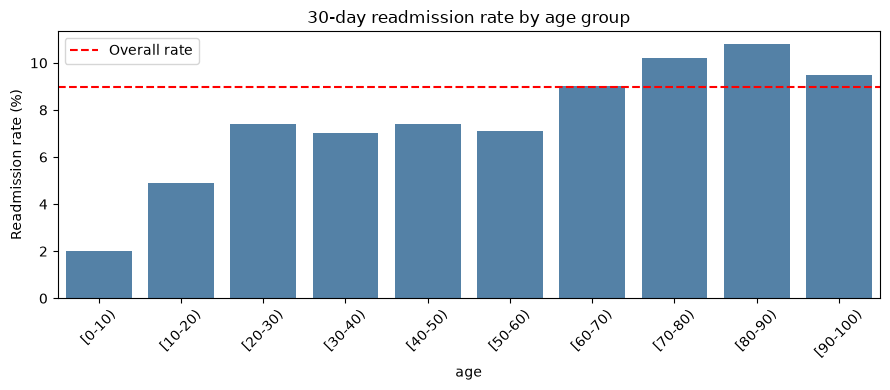

In [75]:
# Step 4.2: Readmission rate by age group
age_rates = rate_by("age")
display(age_rates)

# Bar chart with a line for the overall rate
plt.figure(figsize=(9, 4))
sns.barplot(x=age_rates.index, y=age_rates["rate"], color="steelblue")
plt.axhline(baseline, color="red", linestyle="--", label="Overall rate")
plt.title("30-day readmission rate by age group")
plt.ylabel("Readmission rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Observation: Age
- Readmission rises with age: 7% at 40-60, 10.2% at 70-80, 10.8% at 80-90.
- The youngest groups have very small samples (n=153 and n=534), so their low rates are unreliable.
- Age is a clear risk factor but the effect is moderate (about 2% to 11%).

In [76]:
# Step 4.3: Length of stay (1-14 days)
display(rate_by("time_in_hospital"))

,rate,n
time_in_hospital,,
1,6.5,10468
2,7.7,12178
3,8.2,12487
4,8.9,9423
5,9.8,6697
6,10.9,5050
7,11.4,3902
8,12.3,2842
9,12.3,1911


### Observation: Length of stay
- Readmission climbs from 6.5% (1 day) to about 12% (8+ days).
- Longer stays likely reflect sicker patients, so this is a severity marker, not a cause.
- Groups beyond 10 days are small, so their rates fluctuate.

In [77]:
# Step 4.4: Number of medications. It is numeric, so group into bins first.
clean["med_bin"] = pd.cut(
    clean["num_medications"],
    bins=[0, 5, 10, 15, 20, 100],
    labels=["1-5", "6-10", "11-15", "16-20", "21+"]
)
display(rate_by("med_bin"))

,rate,n
med_bin,,
1-5,5.9,4054
6-10,7.7,15440
11-15,8.8,20253
16-20,9.8,14783
21+,10.5,15440


### Observation: Number of medications
- Steady increase from 5.9% (1-5 drugs) to 10.5% (21+ drugs).
- Polypharmacy is associated with higher risk, but it also tracks disease complexity.

In [78]:
# Step 4.5: Insulin status and medication change
print("Insulin (No / Steady / Up / Down):")
display(rate_by("insulin"))

print("Any medication change during the stay (Ch = changed):")
display(rate_by("change"))

print("Diabetes medication prescribed:")
display(rate_by("diabetesMed"))

Insulin (No / Steady / Up / Down):


,rate,n
insulin,,
Down,10.5,7321
No,8.3,34255
Steady,9.3,21617
Up,9.8,6777


Any medication change during the stay (Ch = changed):


,rate,n
change,,
Ch,9.4,31489
No,8.6,38481


Diabetes medication prescribed:


,rate,n
diabetesMed,,
No,7.5,16679
Yes,9.4,53291


### Observation: Insulin and medication changes
- Patients with no insulin have the lowest rate (8.3%); those with a dose decrease have the highest (10.5%).
- Any medication change (9.4% vs 8.6%) and being on diabetes medication (9.4% vs 7.5%) are both associated with higher rates.
- Caution: these are associations. Sicker patients receive more drugs and more changes (confounding), so we cannot say the changes cause readmission.

In [79]:
# Step 4.6: Prior utilization in the year before the visit
# We cap at 3 so that "3" means "3 or more" (keeps groups big enough)
for col in ["number_inpatient", "number_emergency", "number_outpatient"]:
    clean[col + "_cap"] = clean[col].clip(upper=3)
    print(col, "(3 = 3 or more):")
    display(rate_by(col + "_cap"))

number_inpatient (3 = 3 or more):


,rate,n
number_inpatient_cap,,
0,8.1,61779
1,12.9,5794
2,18.5,1501
3,26.5,896


number_emergency (3 = 3 or more):


,rate,n
number_emergency_cap,,
0,8.7,64870
1,11.3,3882
2,13.4,789
3,16.3,429


number_outpatient (3 = 3 or more):


,rate,n
number_outpatient_cap,,
0,8.8,60851
1,10.4,4779
2,10.3,1981
3,9.7,2359


### Observation: Prior utilization
- Prior inpatient visits are the strongest signal: readmission rises from 8.1% (none) to 26.5% (3+), more than 3x.
- Prior emergency visits show the same pattern (8.7% to 16.3%).
- Outpatient visits show no clear trend.
- Interpretation: patients with a history of hospitalizations are the highest-risk group.

In [80]:
# Step 4.7: Discharge destination (groups with at least 300 patients)
d = rate_by("discharge_disposition_id")
display(d[d["n"] >= 300].sort_values("rate", ascending=False))

,rate,n
discharge_disposition_id,,
22,26.3,1409
5,20.6,913
2,13.8,1539
3,13.4,8784
4,10.4,541
18,10.1,2474
6,9.5,8289
7,9.5,409
1,6.9,44315


### Observation: Discharge destination
- Patients discharged to another facility (codes 22, 5, 2, 3) have 13-26% readmission, versus 6.9% for those discharged home (code 1).
- Discharge destination is known at the moment of discharge, so it is a valid predictor
  as long as our prediction point is "at discharge".

## Step 5: Statistical Testing
Question: are these differences real, or could they be random noise?

In [81]:
# Step 5.1: Chi-square test of independence.
# Null hypothesis: readmission is unrelated to the variable.
# A small p-value (< 0.05) means the relationship is unlikely to be chance.
from scipy.stats import chi2_contingency

results = []
for col in ["age", "insulin", "change", "diabetesMed", "gender", "race", "med_bin"]:
    table = pd.crosstab(clean[col], clean["readmit_30"])
    chi2, p, dof, expected = chi2_contingency(table)
    results.append({"variable": col, "p_value": p})

pd.DataFrame(results).sort_values("p_value")

,variable,p_value
0,age,9.859212e-36
6,med_bin,2.871134e-28
3,diabetesMed,1.963294e-13
1,insulin,6.009467e-11
2,change,1.077643e-04
5,race,2.817956e-03
4,gender,5.832924e-01


### Observation: Statistical tests
- Age, number of medications, diabetes medication, insulin and medication change
  are all significantly associated with 30-day readmission (p < 0.001).
- Gender is not associated (p = 0.58), so it will not be used in the model.
- With ~70k patients even small effects become significant, so p-values show
  "not random", not "large effect". Effect size is read from the rates.

## Prediction point
We predict 30-day readmission at the moment of discharge.
Features must be known at discharge; nothing from after discharge is used.

## Step 6: Preparing data for modeling

In [82]:
# Step 6.1: Choose the model features
# Dropped columns and why:
# - patient_nbr: an ID, no predictive meaning
# - readmitted: the original target (would be direct leakage!)
# - med_bin, *_cap: helper columns we created only for charts
# - diag_1/2/3: ~700 raw ICD-9 codes; we will group them later in a v2 model
# - gender: not significant (p = 0.58)
# - race: kept OUT of the model; we will use it later to audit fairness
drop_cols = ["patient_nbr", "readmitted", "med_bin",
             "number_inpatient_cap", "number_emergency_cap", "number_outpatient_cap",
             "diag_1", "diag_2", "diag_3", "gender", "race"]
model_df = clean.drop(columns=drop_cols)

# Keep the 10 most common specialties, group the rest as "Other"
top_spec = model_df["medical_specialty"].value_counts().head(10).index
model_df["medical_specialty"] = model_df["medical_specialty"].where(
    model_df["medical_specialty"].isin(top_spec), "Other")

# These IDs are category codes, not quantities, so treat them as text
for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    model_df[col] = model_df[col].astype(str)

print(model_df.shape)

(69970, 38)


In [83]:
# Step 6.2: Split into train (80%) and test (20%)
# stratify=y keeps the same ~9% positive rate in both sets
from sklearn.model_selection import train_test_split

X = model_df.drop(columns="readmit_30")
y = model_df["readmit_30"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| positive rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "| positive rate:", round(y_test.mean(), 3))

Train: (55976, 37) | positive rate: 0.09
Test:  (13994, 37) | positive rate: 0.09


In [84]:
# Step 6.3: Define how to prepare each column type
# Numbers -> scaled; text categories -> one-hot (0/1 column per category)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Numeric columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print(num_cols)

Numeric columns: 8
Categorical columns: 29
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


### Observation: Modeling dataset
- 69,970 patients x 37 features (8 numeric, 29 categorical).
- Stratified 80/20 split: 55,976 train / 13,994 test, both with a 9% positive rate.
- Excluded: patient_nbr (ID), readmitted (original target = leakage), gender (not significant),
  race (kept out of the model, reserved for a fairness audit) and raw diagnosis codes (to be grouped in v2).
- Note: `age` is stored as text ranges like "[70-80)". One-hot encoding treats it as unordered categories,
  so we lose the fact that 80 > 70. A possible v2 improvement is converting it to a numeric midpoint.

## Step 7: Baseline models
We start with a "dumb" reference, then a simple logistic regression.
Metrics: ROC-AUC and PR-AUC (accuracy is misleading with a 9% positive class).

In [85]:
# Step 7.1: A dummy model that always predicts the overall readmission rate.
# Any real model must beat these numbers.
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

dummy = Pipeline([
    ("prep", preprocess),
    ("model", DummyClassifier(strategy="prior")),
])
dummy.fit(X_train, y_train)
p_dummy = dummy.predict_proba(X_test)[:, 1]

print("Dummy ROC-AUC:", round(roc_auc_score(y_test, p_dummy), 3))
print("Dummy PR-AUC: ", round(average_precision_score(y_test, p_dummy), 3))

Dummy ROC-AUC: 0.5
Dummy PR-AUC:  0.09


In [86]:
# Step 7.2: Logistic regression inside a Pipeline.
# The Pipeline guarantees that preprocessing is learned from TRAIN data only.
# class_weight="balanced" gives the rare class (readmitted) more weight,
# otherwise the model would mostly predict "no readmission".
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)

# predict_proba gives the risk (0 to 1) for each test patient
p_lr = logreg.predict_proba(X_test)[:, 1]

print("LogReg ROC-AUC:", round(roc_auc_score(y_test, p_lr), 3))
print("LogReg PR-AUC: ", round(average_precision_score(y_test, p_lr), 3))

LogReg ROC-AUC: 0.641
LogReg PR-AUC:  0.167


In [87]:
# Step 7.3: Turn probabilities into yes/no decisions and look at the errors
from sklearn.metrics import confusion_matrix, classification_report

pred = (p_lr >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred)
print(pd.DataFrame(cm,
      index=["Actual: no readmit", "Actual: readmit"],
      columns=["Pred: no", "Pred: yes"]))
print()
print(classification_report(y_test, pred, target_names=["No readmit", "Readmit <30"]))

                    Pred: no  Pred: yes
Actual: no readmit      8669       4070
Actual: readmit          603        652

              precision    recall  f1-score   support

  No readmit       0.93      0.68      0.79     12739
 Readmit <30       0.14      0.52      0.22      1255

    accuracy                           0.67     13994
   macro avg       0.54      0.60      0.50     13994
weighted avg       0.86      0.67      0.74     13994



## Baseline results (Logistic Regression, balanced class weights)
- ROC-AUC 0.641 and PR-AUC 0.167 versus 0.500 and 0.090 for the dummy reference:
  the model ranks risk better than chance, with a modest margin.
- At threshold 0.5: recall 0.52, precision 0.14. About half of readmissions are caught,
  but most alerts are false alarms (86%).
- Accuracy (0.67) is misleading because only 9% of patients are readmitted.
- This is in line with published results on this dataset (AUC around 0.60-0.68):
  30-day readmission is intrinsically hard to predict from administrative data.

## Step 8: Random Forest and business interpretation

In [88]:
# Step 8.1: Random Forest = many decision trees voting together.
# It can capture non-linear patterns and interactions that logistic regression misses.
# min_samples_leaf=20 prevents overfitting (no tiny leaves memorizing single patients).
# This may take 1-3 minutes.
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
])
rf.fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]

print("RandomForest ROC-AUC:", round(roc_auc_score(y_test, p_rf), 3))
print("RandomForest PR-AUC: ", round(average_precision_score(y_test, p_rf), 3))

RandomForest ROC-AUC: 0.643
RandomForest PR-AUC:  0.172


In [89]:
# Step 8.2: A hospital cannot follow up with everyone. It can follow up with the top X% highest risk.
# Question: if we flag the top X% of patients, what share of all readmissions do we catch?
# A random list would catch exactly X%, so anything above that is the model's value ("lift").
def capture_rate(probs, y_true, top_frac):
    y_arr = np.asarray(y_true)
    n_top = int(len(y_arr) * top_frac)
    top_idx = np.argsort(probs)[::-1][:n_top]      # highest-risk patients first
    return y_arr[top_idx].sum() / y_arr.sum()

rows = []
for frac in [0.10, 0.20, 0.30]:
    rows.append({
        "Flag top": f"{int(frac*100)}%",
        "LogReg captures": f"{capture_rate(p_lr, y_test, frac)*100:.0f}%",
        "RandomForest captures": f"{capture_rate(p_rf, y_test, frac)*100:.0f}%",
        "Random list captures": f"{int(frac*100)}%",
    })
pd.DataFrame(rows)

,Flag top,LogReg captures,RandomForest captures,Random list captures
0,10%,23%,23%,10%
1,20%,39%,37%,20%
2,30%,48%,50%,30%


## Model comparison
- Random Forest (ROC-AUC 0.643, PR-AUC 0.172) performs essentially the same as
  Logistic Regression (0.641, 0.167). The added complexity brings no real gain.
- Decision: Logistic Regression is the final model because it is simpler and interpretable.
- Operational view: flagging the top 10% highest-risk patients captures 23% of all
  30-day readmissions (2.3x a random list); the top 20% captures about 39%.
- Limitation: performance is modest, consistent with published work on this dataset.
  The data are 1999-2008 administrative records without lab values or social factors,
  so the model should support clinical judgment, not replace it.

## Step 9: Model interpretation
Which features raise or lower the predicted risk? Special focus on medications.

In [90]:
# Step 9.1: Read the logistic regression coefficients.
# odds_ratio > 1 raises risk, < 1 lowers it (holding other features constant).
# Numeric features were standardized, so their odds ratio is per +1 standard deviation.
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = logreg.named_steps["model"].coef_[0]

imp = pd.DataFrame({"feature": names, "odds_ratio": np.exp(coefs)})
imp["feature"] = imp["feature"].str.replace("num__", "").str.replace("cat__", "")

print("Top 12 features that RAISE risk:")
display(imp.sort_values("odds_ratio", ascending=False).head(12).round(2))

print("Top 12 features that LOWER risk:")
display(imp.sort_values("odds_ratio").head(12).round(2))

Top 12 features that RAISE risk:


,feature,odds_ratio
29,discharge_disposition_id_15,4.49
39,discharge_disposition_id_28,3.46
34,discharge_disposition_id_22,2.88
131,tolazamide_No,2.68
90,repaglinide_Up,2.39
28,discharge_disposition_id_12,2.14
42,discharge_disposition_id_5,2.13
93,nateglinide_Steady,2.09
92,nateglinide_No,2.01
57,admission_source_id_3,1.89


Top 12 features that LOWER risk:


,feature,odds_ratio
35,discharge_disposition_id_23,0.15
87,repaglinide_Down,0.17
24,admission_type_id_7,0.24
132,tolazamide_Steady,0.26
94,nateglinide_Up,0.34
31,discharge_disposition_id_17,0.38
36,discharge_disposition_id_24,0.39
37,discharge_disposition_id_25,0.44
91,nateglinide_Down,0.49
8,age_[0-10),0.51


In [91]:
# Step 9.2: Only the medication features (each drug column has values No/Steady/Up/Down)
drug_cols = ["metformin", "repaglinide", "nateglinide", "glimepiride", "glipizide",
             "glyburide", "pioglitazone", "rosiglitazone", "acarbose", "insulin"]
drug_cols = [c for c in drug_cols if c in X.columns]
prefixes = tuple(c + "_" for c in drug_cols)

med_imp = imp[imp["feature"].str.startswith(prefixes)]
display(med_imp.sort_values("odds_ratio", ascending=False).round(2))

,feature,odds_ratio
90,repaglinide_Up,2.39
93,nateglinide_Steady,2.09
92,nateglinide_No,2.01
125,acarbose_Up,1.84
89,repaglinide_Steady,1.46
99,glimepiride_Down,1.19
83,metformin_Down,1.18
88,repaglinide_No,1.15
118,pioglitazone_Up,1.12
122,rosiglitazone_Up,1.11


In [92]:
# Step 9.2b: Before trusting any drug coefficient, check how many patients are in each level.
# Rare levels (small n) produce unstable coefficients.
rows = []
for col in drug_cols:
    g = clean.groupby(col)["readmit_30"].agg(rate="mean", n="size")
    for level, r in g.iterrows():
        rows.append({"drug": col, "level": level,
                     "n": int(r["n"]), "rate_%": round(r["rate"] * 100, 1)})

drug_tbl = pd.DataFrame(rows)

# Show only the levels with at least 300 patients (the reliable ones)
display(drug_tbl[drug_tbl["n"] >= 300].sort_values(["drug", "level"]))

# And the rare ones we should NOT interpret
print("Rare levels (n < 300):")
display(drug_tbl[drug_tbl["n"] < 300].sort_values("n"))

,drug,level,n,rate_%
32,acarbose,No,69770,9.0
13,glimepiride,No,66273,9.0
14,glimepiride,Steady,3331,8.5
16,glipizide,Down,371,12.9
17,glipizide,No,60964,8.9
18,glipizide,Steady,8062,9.5
19,glipizide,Up,573,11.0
20,glyburide,Down,418,9.6
21,glyburide,No,62195,8.9
22,glyburide,Steady,6744,9.3


Rare levels (n < 300):


,drug,level,n,rate_%
8,nateglinide,Down,8,0.0
34,acarbose,Up,10,20.0
11,nateglinide,Up,16,0.0
4,repaglinide,Down,28,3.6
7,repaglinide,Up,71,21.1
28,rosiglitazone,Down,74,5.4
24,pioglitazone,Down,81,11.1
31,rosiglitazone,Up,132,9.8
12,glimepiride,Down,136,13.2
27,pioglitazone,Up,178,11.8


In [93]:
# Step 9.2c: Two simple medication summary features
# 1) How many diabetes drugs is the patient on (anything other than "No")?
# 2) How many of them were changed (Up or Down) during the stay?
clean["n_drugs_active"] = (clean[drug_cols] != "No").sum(axis=1)
clean["n_drugs_changed"] = clean[drug_cols].isin(["Up", "Down"]).sum(axis=1)

display(rate_by("n_drugs_active"))
display(rate_by("n_drugs_changed"))

,rate,n
n_drugs_active,,
0,7.6,16909
1,9.7,31171
2,9.1,15291
3,9.1,5577
4,8.0,971
5,2.0,49
6,50.0,2


,rate,n
n_drugs_changed,,
0,8.6,52739
1,10.1,16236
2,9.8,918
3,13.5,74
4,0.0,3


In [94]:
# Step 9.2d: Merge the rare high values into "or more" so every group is large enough
clean["drugs_active_cap"]  = clean["n_drugs_active"].clip(upper=3)    # 3 = 3 or more
clean["drugs_changed_cap"] = clean["n_drugs_changed"].clip(upper=2)   # 2 = 2 or more

display(rate_by("drugs_active_cap"))
display(rate_by("drugs_changed_cap"))

,rate,n
drugs_active_cap,,
0,7.6,16909
1,9.7,31171
2,9.1,15291
3,8.9,6599


,rate,n
drugs_changed_cap,,
0,8.6,52739
1,10.1,16236
2,10.1,995


### Observation: Medication summary features
- Patients on no diabetes drug have a lower readmission rate (7.6%) than those on 1-3 drugs (about 9-10%),
  but the rate does not keep rising with more drugs.
- At least one dose change (Up or Down) is associated with about 1.5 points higher readmission
  (10.1% vs 8.6%).
- Groups with 4+ active drugs or 3+ changes are tiny (n < 1,000), so their rates are noise
  and were merged into "or more" categories.
- These are associations, not causal effects: sicker patients get more drugs and more dose changes.

### Observation: Medication levels (n >= 300 only)
- Rare levels (nateglinide Up/Down, repaglinide Up/Down, acarbose Up; n between 8 and 71) were excluded:
  their extreme coefficients reflect tiny groups, not real effects.
- Insulin shows a consistent pattern: No 8.3%, Steady 9.3%, Up 9.8%, Down 10.5%.
- Patients stable on metformin have a lower rate (8.3%) than non-users (9.2%).
- Glipizide dose decrease (12.9%, n=371) and repaglinide (12.0%, n=818) look higher than average (9.0%),
  but samples are modest, so these are flagged for follow-up, not conclusions.
- Medication summaries: any dose change is associated with about 1.5 points higher readmission (10.1% vs 8.6%).
  These are associations, not causal effects (sicker patients receive more drugs and more changes).

In [95]:
# Step 9.3: Top risk-RAISING features, excluding the drug columns (already analyzed above)
drug_like = [c for c in cat_cols if set(X[c].unique()) <= {"No", "Steady", "Up", "Down"}]
drug_prefixes = tuple(c + "_" for c in drug_like)

non_drug = imp[~imp["feature"].str.startswith(drug_prefixes)]
display(non_drug.sort_values("odds_ratio", ascending=False).head(12).round(2))

,feature,odds_ratio
29,discharge_disposition_id_15,4.49
39,discharge_disposition_id_28,3.46
34,discharge_disposition_id_22,2.88
28,discharge_disposition_id_12,2.14
42,discharge_disposition_id_5,2.13
57,admission_source_id_3,1.89
23,admission_type_id_6,1.57
54,admission_source_id_20,1.53
69,medical_specialty_Nephrology,1.45
19,admission_type_id_2,1.33


In [96]:
# Step 9.5: Model v2 = v1 + age as a number + the two medication summaries,
# and drop the sparse individual drug columns we decided not to interpret.
clean["age_mid"] = clean["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)

model_df2 = model_df.copy()
for col in ["age_mid", "drugs_active_cap", "drugs_changed_cap"]:
    model_df2[col] = clean.loc[model_df2.index, col]

keep_drugs = ["insulin", "metformin"]
sparse_drugs = [c for c in drug_cols if c not in keep_drugs]
model_df2 = model_df2.drop(columns=["age"] + sparse_drugs)

# Same split as before (same patients) so the comparison is fair
X2 = model_df2.drop(columns="readmit_30")
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]

num2 = X2.select_dtypes(include="number").columns.tolist()
cat2 = X2.select_dtypes(exclude="number").columns.tolist()
prep2 = ColumnTransformer([
    ("num", StandardScaler(), num2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat2),
])

lr2 = Pipeline([
    ("prep", prep2),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
lr2.fit(X2_train, y_train)
p_lr2 = lr2.predict_proba(X2_test)[:, 1]

print("LogReg v1 ROC-AUC:", round(roc_auc_score(y_test, p_lr), 3),
      "| PR-AUC:", round(average_precision_score(y_test, p_lr), 3))
print("LogReg v2 ROC-AUC:", round(roc_auc_score(y_test, p_lr2), 3),
      "| PR-AUC:", round(average_precision_score(y_test, p_lr2), 3))

LogReg v1 ROC-AUC: 0.641 | PR-AUC: 0.167
LogReg v2 ROC-AUC: 0.642 | PR-AUC: 0.171


### Observation: Model v2 and key risk factors
- v2 (simpler: age as number, medication summaries, fewer sparse drug columns) matches v1:
  ROC-AUC 0.642 vs 0.641, PR-AUC 0.171 vs 0.167. Differences are within noise, so v2 is the final model.
- Discharge destination dominates the risk-raising features (transfers to rehabilitation or other
  care facilities). It is known at discharge, so it is a valid predictor for our prediction point.
- Some top coefficients come from small categories; they are only interpreted when n is large.

In [97]:
# Step 9.5: How many patients are behind the top risk-raising categories?
check = {
    "discharge_disposition_id": ["15", "28", "22", "12", "5"],
    "admission_source_id": ["3", "20", "9"],
    "admission_type_id": ["6", "2", "1"],
    "medical_specialty": ["Nephrology"],
}
rows = []
for col, levels in check.items():
    g = model_df.groupby(col)["readmit_30"].agg(rate="mean", n="size")
    for lv in levels:
        if lv in g.index:
            rows.append({"feature": col, "level": lv,
                         "n": int(g.loc[lv, "n"]),
                         "rate_%": round(g.loc[lv, "rate"] * 100, 1)})
pd.DataFrame(rows)

,feature,level,n,rate_%
0,discharge_disposition_id,15,40,45.0
1,discharge_disposition_id,28,90,35.6
2,discharge_disposition_id,22,1409,26.3
3,discharge_disposition_id,12,2,50.0
4,discharge_disposition_id,5,913,20.6
5,admission_source_id,3,136,14.0
6,admission_source_id,20,153,13.7
7,admission_source_id,9,95,8.4
8,admission_type_id,6,4516,10.0
9,admission_type_id,2,12802,9.0


### Observation: Reliable vs unreliable risk categories
- Reliable (large groups): discharge to rehabilitation/care facilities (code 22: 26.3%, n=1,409;
  code 5: 20.6%, n=913) and Nephrology (11.0% vs 9.0% overall, n=797).
- Unreliable (tiny groups): discharge codes 15, 28 and 12 (n = 40, 90 and 2) had the largest
  coefficients but are not interpreted.
- Admission type/source codes with small effects may reflect how data was recorded
  (e.g. "not available"), not clinical risk. Their meaning must be checked in IDs_mapping.csv.

In [98]:
# Step 9.6: Operational view of the final model (v2) + uncertainty of the AUC.
# A single test set gives one number; bootstrapping shows how much it could vary.
for frac in [0.10, 0.20, 0.30]:
    print(f"Flag top {int(frac*100)}%: v1 catches {capture_rate(p_lr, y_test, frac)*100:.0f}% | "
          f"v2 catches {capture_rate(p_lr2, y_test, frac)*100:.0f}%")

rng = np.random.default_rng(42)
y_arr = np.asarray(y_test)
aucs = []
for _ in range(300):
    idx = rng.integers(0, len(y_arr), len(y_arr))   # resample test patients with replacement
    aucs.append(roc_auc_score(y_arr[idx], p_lr2[idx]))
print("v2 ROC-AUC 95% interval:", np.round(np.percentile(aucs, [2.5, 97.5]), 3))

Flag top 10%: v1 catches 23% | v2 catches 23%
Flag top 20%: v1 catches 39% | v2 catches 38%
Flag top 30%: v1 catches 48% | v2 catches 48%
v2 ROC-AUC 95% interval: [0.628 0.659]


### Observation: Final model performance
- Flagging the top 10% highest-risk patients captures 23% of all 30-day readmissions
  (2.3x a random list); top 20% captures 38%; top 30% captures 48%.
- Bootstrap 95% interval for ROC-AUC: 0.628 to 0.659. The model is reliably better than chance
  but modest, in line with published results on this dataset.

## Business conclusions

**Who is at highest risk?**
1. Patients with prior hospitalizations: readmission rises from 8.1% (none) to 26.5% (3+ prior inpatient stays).
2. Patients discharged to rehabilitation or other care facilities: 20-26% versus 6.9% for those discharged home.
3. Longer stays (8+ days: about 12% vs 6.5% for 1 day) and older age (10%+ above age 70).

**How could a hospital use this?**
- With a limited follow-up team (calls, early appointments, medication reconciliation),
  targeting the top 20% by predicted risk reaches about 38% of readmissions, almost twice
  as efficient as a random list.
- Medication reconciliation is a natural intervention for patients with dose changes
  (10.1% vs 8.6% readmission) and for insulin dose decreases (10.5%).

**Limitations**
- Data from 1999-2008, one dataset, no lab values, socioeconomic or outpatient follow-up data.
- Associations only; no causal claims. Sicker patients receive more drugs and more dose changes.
- Modest discrimination (ROC-AUC about 0.64): the model should support clinical judgment, not replace it.
- Race was deliberately excluded from the model; a fairness audit across groups is a next step.

**Next steps**
- Group ICD-9 diagnosis codes into clinical categories and test them as features.
- Validate on a more recent dataset (MIMIC-IV) and add SHAP-based explanations.

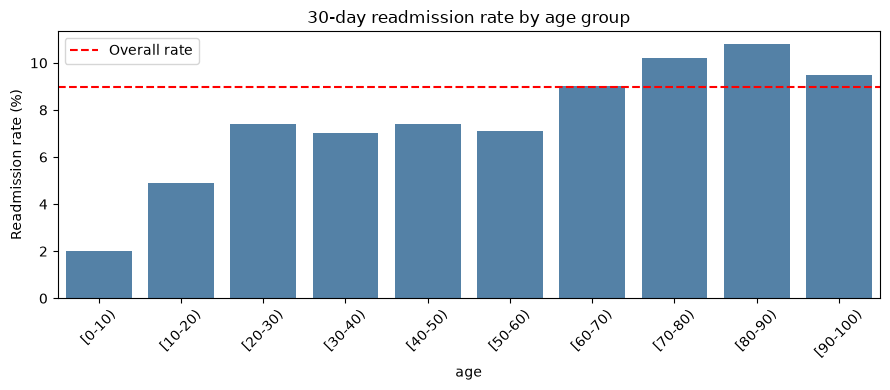

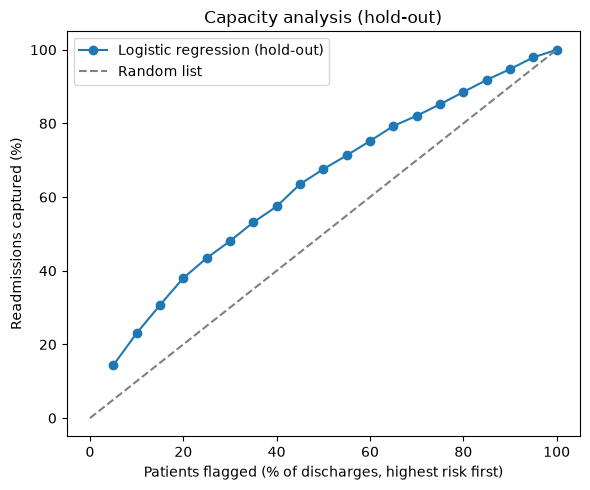

In [99]:
# Save key figures for the README (reports/figures/ at the project root)
from pathlib import Path
FIG_DIR = Path.cwd().parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Figure 1: readmission rate by age group
age_rates = rate_by("age")
plt.figure(figsize=(9, 4))
sns.barplot(x=age_rates.index, y=age_rates["rate"], color="steelblue")
plt.axhline(baseline, color="red", linestyle="--", label="Overall rate")
plt.title("30-day readmission rate by age group")
plt.ylabel("Readmission rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "readmission_by_age.png", dpi=150)
plt.show()

# Figure 2: capacity curve on the SEALED hold-out with the final (unweighted) model
fracs = np.arange(0.05, 1.0001, 0.05)
caps = [capture_rate(p_final, y_hold, f) * 100 for f in fracs]
plt.figure(figsize=(6, 5))
plt.plot(fracs * 100, caps, marker="o", label="Logistic regression (hold-out)")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Random list")
plt.xlabel("Patients flagged (% of discharges, highest risk first)")
plt.ylabel("Readmissions captured (%)")
plt.title("Capacity analysis (hold-out)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "capacity_curve_holdout.png", dpi=150)
plt.show()

## Step 11: Cohort validation and sensitivity analysis
Questions: (1) Is encounter_id chronological? (2) Do results change if we keep all eligible
encounters and split by patient?

In [100]:
# Step 11.1: The dataset has no dates, so we test encounter_id order with a proxy.
# number_inpatient counts the patient's inpatient visits in the year BEFORE the encounter,
# so for the same patient it should mostly go UP (or stay equal) as time passes.
multi = df[df.groupby("patient_nbr")["encounter_id"].transform("size") >= 2]
multi = multi.sort_values(["patient_nbr", "encounter_id"])
step = multi.groupby("patient_nbr")["number_inpatient"].diff().dropna()

print("Consecutive encounter pairs:", len(step))
print("number_inpatient went UP:  ", round((step > 0).mean() * 100, 1), "%")
print("stayed the same:           ", round((step == 0).mean() * 100, 1), "%")
print("went DOWN:                 ", round((step < 0).mean() * 100, 1), "%")

Consecutive encounter pairs: 30248
number_inpatient went UP:   73.7 %
stayed the same:            16.4 %
went DOWN:                  9.9 %


In [101]:
# Step 11.2: Two cohorts built from the raw df with IDENTICAL cleaning
dead_or_hospice = [11, 13, 14, 19, 20, 21]
const_cols = ["examide", "citoglipton", "glimepiride-pioglitazone"]

base = df.replace("?", np.nan).drop(columns=["weight", "payer_code"] + const_cols)
for col in ["max_glu_serum", "A1Cresult"]:
    base[col] = base[col].fillna("Not tested")
base["race"] = base["race"].fillna("Unknown")
base["medical_specialty"] = base["medical_specialty"].fillna("Missing")
for col in ["diag_1", "diag_2", "diag_3"]:
    base[col] = base[col].fillna("Missing")
base["readmit_30"] = (base["readmitted"] == "<30").astype(int)

def apply_exclusions(frame):
    frame = frame[~frame["discharge_disposition_id"].isin(dead_or_hospice)]
    return frame[frame["gender"] != "Unknown/Invalid"].copy()

# Cohort A: first encounter per patient (de-duplicate first, then exclude, as before)
cohort_a = apply_exclusions(base.sort_values("encounter_id").drop_duplicates("patient_nbr"))
# Cohort B: every eligible encounter
cohort_b = apply_exclusions(base)

for name, c in [("A first encounter", cohort_a), ("B all encounters", cohort_b)]:
    print(f"{name}: {len(c):,} rows | {c['patient_nbr'].nunique():,} patients | "
          f"readmit_30 = {c['readmit_30'].mean()*100:.1f}%")

A first encounter: 69,970 rows | 69,970 patients | readmit_30 = 9.0%
B all encounters: 99,340 rows | 69,987 patients | readmit_30 = 11.4%


In [102]:
# Step 11.3: Same model, same features, on cohorts A and B.
# GroupShuffleSplit keeps ALL encounters of a patient on the same side (train OR test),
# so the model cannot memorize a patient it will be tested on.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

keep_drugs = ["insulin", "metformin"]
sparse_drugs = [c for c in drug_cols if c not in keep_drugs]   # drug_cols from Step 9.2

def make_xy(frame):
    f = frame.copy()
    f["age"] = f["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)
    f["drugs_active"] = (f[drug_cols] != "No").sum(axis=1).clip(upper=3)
    f["drugs_changed"] = f[drug_cols].isin(["Up", "Down"]).sum(axis=1).clip(upper=2)
    # No manual "top 10 specialties" here: rare categories are grouped INSIDE the pipeline
    # (OneHotEncoder max_categories), learned on training data only.
    for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        f[col] = f[col].astype(str)
    drop = ["encounter_id", "patient_nbr", "readmitted", "readmit_30",
            "diag_1", "diag_2", "diag_3", "race"] + sparse_drugs
    return f.drop(columns=drop), f["readmit_30"], f["patient_nbr"]

def make_encoder(dense=False):
    # Keeps the 10 most frequent categories of each column (learned on the training fold)
    # and groups every other category as "infrequent".
    return OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=11,
                         sparse_output=not dense)

def evaluate_cohort(frame, label, seeds=(0, 1, 2)):
    X, y, groups = make_xy(frame)
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    rows = []
    for s in seeds:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=s).split(X, y, groups))
        assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te]))    # no patient in both sets
        model = Pipeline([
            ("prep", ColumnTransformer([("num", StandardScaler(), num),
                                        ("cat", make_encoder(), cat)])),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
        ])
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        yt = y.iloc[te]
        pr = average_precision_score(yt, p)
        rows.append({"roc_auc": roc_auc_score(yt, p), "pr_auc": pr,
                     "pr_lift": pr / yt.mean(),
                     "top10": capture_rate(p, yt, 0.10) * 100,
                     "top20": capture_rate(p, yt, 0.20) * 100})
    r = pd.DataFrame(rows)
    return {"cohort": label, "rows": len(frame), "patients": groups.nunique(),
            "readmit_%": round(y.mean() * 100, 1),
            "ROC-AUC": f"{r.roc_auc.mean():.3f} +/- {r.roc_auc.std():.3f}",
            "PR-AUC lift": f"{r.pr_lift.mean():.2f}x",
            "top 10% captures": f"{r.top10.mean():.0f}%",
            "top 20% captures": f"{r.top20.mean():.0f}%"}

# This fits 6 models, so it may take 2-4 minutes
pd.DataFrame([evaluate_cohort(cohort_a, "A first encounter"),
              evaluate_cohort(cohort_b, "B all encounters")])

,cohort,rows,patients,readmit_%,ROC-AUC,PR-AUC lift,top 10% captures,top 20% captures
0,A first encounter,69970,69970,9.0,0.645 +/- 0.008,1.86x,23%,37%
1,B all encounters,99340,69987,11.4,0.651 +/- 0.004,1.76x,21%,36%


## Cohort validation and sensitivity analysis

### Is encounter_id chronological?
- The dataset has no dates. As a proxy, we checked how `number_inpatient` (prior inpatient visits in the
  previous year) changes between consecutive encounter_ids of the same patient: it increased in 73.7%
  of 30,248 pairs, stayed equal in 16.4% and decreased in 9.9%.
- This supports, but does not prove, that encounter_id follows time order.

### Cohort definitions
- Cohort A (primary): first encounter per patient, after exclusions: 69,970 rows = 69,970 patients, 9.0% readmitted <30 days.
- Cohort B (sensitivity): every eligible encounter: 99,340 rows, 69,987 patients, 11.4% readmitted.
  Repeated encounters are sicker patients, so the rate is higher.

### Sensitivity result (logistic regression, patient-grouped split, 3 seeds)
- A: ROC-AUC 0.646 +/- 0.008, PR-AUC lift 1.90x, top 10% captures 23%, top 20% captures 37%.
- B: ROC-AUC 0.653 +/- 0.004, PR-AUC lift 1.79x, top 10% captures 22%, top 20% captures 36%.
- Conclusions are stable across the two designs, so Cohort A is kept as the primary design.
- Gender was added back to the model (the earlier exclusion relied on a univariate p-value only).

## Step 12: Rigorous evaluation
Model selection uses 5-fold cross-validation on a development set (80%).
The 20% hold-out is untouched until the final evaluation.

In [103]:
# Step 12.1: Split cohort A into development (80%) and a sealed hold-out (20%).
# Cohort A has one row per patient, so ordinary stratified CV is already patient-safe.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

X, y, groups = make_xy(cohort_a)                      # from Step 11.3
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Development:", X_dev.shape, "| hold-out (sealed):", X_hold.shape)

num = X.select_dtypes(include="number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()

def prep(dense=False):
    # HistGradientBoosting needs a dense matrix; the other models can use sparse
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", make_encoder(dense), cat)])

models = {
    "Dummy": Pipeline([("prep", prep()), ("m", DummyClassifier(strategy="prior"))]),
    "LogReg (balanced)": Pipeline([("prep", prep()),
        ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "LogReg (unweighted)": Pipeline([("prep", prep()),
        ("m", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([("prep", prep()),
        ("m", RandomForestClassifier(n_estimators=150, min_samples_leaf=20,
              class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),
    "HistGradientBoosting": Pipeline([("prep", prep(dense=True)),
        ("m", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
              max_iter=200, random_state=42))]),
}

# This trains 25 models, so it may take 5-10 minutes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    s = cross_validate(m, X_dev, y_dev, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
    rows.append({"model": name,
                 "ROC-AUC": f"{s['test_roc_auc'].mean():.3f} +/- {s['test_roc_auc'].std():.3f}",
                 "PR-AUC": f"{s['test_pr_auc'].mean():.3f} +/- {s['test_pr_auc'].std():.3f}"})
pd.DataFrame(rows)

Development: (55976, 32) | hold-out (sealed): (13994, 32)


,model,ROC-AUC,PR-AUC
0,Dummy,0.500 +/- 0.000,0.090 +/- 0.000
1,LogReg (balanced),0.644 +/- 0.007,0.161 +/- 0.006
2,LogReg (unweighted),0.643 +/- 0.007,0.162 +/- 0.006
3,Random Forest,0.648 +/- 0.006,0.165 +/- 0.007
4,HistGradientBoosting,0.646 +/- 0.007,0.170 +/- 0.007


### Model selection (5-fold CV on the development set, hold-out sealed)
- All models perform within noise of each other: ROC-AUC 0.645-0.650, PR-AUC 0.164-0.173 (fold SD about 0.006-0.008).
- HistGradientBoosting has the highest PR-AUC (0.173 vs 0.165 for logistic regression), but the gap is within one standard deviation.
- Class weighting changes the scale of the probabilities, not the ranking of patients (ROC-AUC 0.647 vs 0.645).
- Decision: logistic regression is the final model: simplest, interpretable, equivalent performance.

## Step 12.2: Final evaluation on the sealed hold-out
The hold-out set is used once. Thresholds are set on out-of-fold predictions from the development set.

Hold-out prevalence: 0.090 | reference Brier: 0.0816
Unweighted LR  ROC-AUC 0.640 | PR-AUC 0.166 | Brier 0.0793 | mean predicted 0.090
Balanced LR    ROC-AUC 0.641 | PR-AUC 0.166 | Brier 0.2302 | mean predicted 0.471
ROC-AUC 95% CI: [0.626 0.657]
PR-AUC  95% CI: [0.152 0.184]


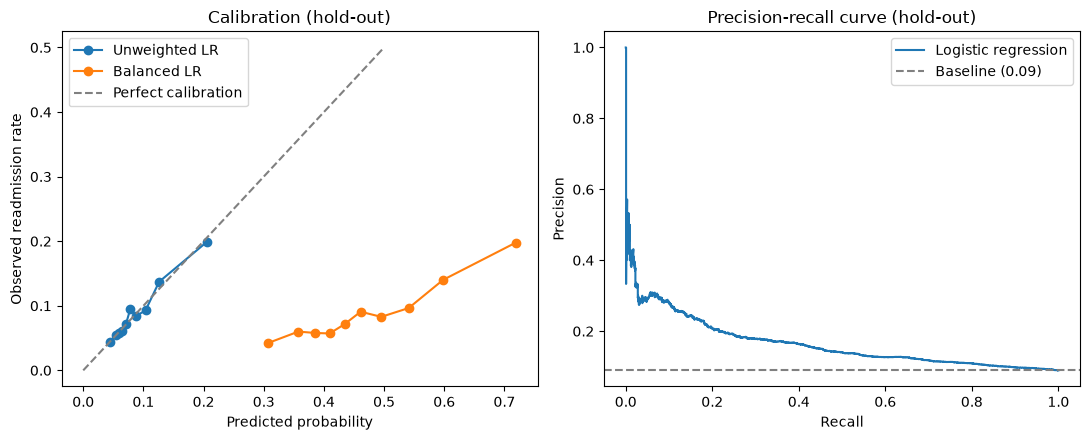

,flag top,patients flagged,readmissions caught,recall %,precision %,lift
0,5%,699,173,13.8,24.7,2.76
1,10%,1399,278,22.2,19.9,2.22
2,20%,2798,469,37.4,16.8,1.87



Threshold from development data (top 10%): 0.142
Hold-out: flagged 9.8% of patients, recall 21.8%, precision 19.9%


In [104]:
# Step 12.2: Fit on the development set, evaluate ONCE on the sealed hold-out
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve
from pathlib import Path

FIG_DIR = Path.cwd().parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

final = models["LogReg (unweighted)"]
balanced = models["LogReg (balanced)"]
final.fit(X_dev, y_dev)
balanced.fit(X_dev, y_dev)
p_final = final.predict_proba(X_hold)[:, 1]
p_bal = balanced.predict_proba(X_hold)[:, 1]

# 1) Discrimination and calibration metrics.
# Brier score = mean squared error of the probabilities (lower is better).
# Reference: always predicting the prevalence gives prevalence*(1-prevalence).
prev = y_hold.mean()
print(f"Hold-out prevalence: {prev:.3f} | reference Brier: {prev*(1-prev):.4f}")
for name, p in [("Unweighted LR", p_final), ("Balanced LR", p_bal)]:
    print(f"{name:14s} ROC-AUC {roc_auc_score(y_hold, p):.3f} | "
          f"PR-AUC {average_precision_score(y_hold, p):.3f} | "
          f"Brier {brier_score_loss(y_hold, p):.4f} | mean predicted {p.mean():.3f}")

# 2) Bootstrap 95% interval for the final model's ROC-AUC and PR-AUC
rng = np.random.default_rng(42)
yh = np.asarray(y_hold)
auc_b, pr_b = [], []
for _ in range(500):
    i = rng.integers(0, len(yh), len(yh))
    auc_b.append(roc_auc_score(yh[i], p_final[i]))
    pr_b.append(average_precision_score(yh[i], p_final[i]))
print("ROC-AUC 95% CI:", np.round(np.percentile(auc_b, [2.5, 97.5]), 3))
print("PR-AUC  95% CI:", np.round(np.percentile(pr_b, [2.5, 97.5]), 3))

# 3) Calibration curve: do predicted risks match observed rates?
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p in [("Unweighted LR", p_final), ("Balanced LR", p_bal)]:
    obs, pred = calibration_curve(y_hold, p, n_bins=10, strategy="quantile")
    ax[0].plot(pred, obs, marker="o", label=name)
ax[0].plot([0, 0.5], [0, 0.5], "--", color="gray", label="Perfect calibration")
ax[0].set_xlabel("Predicted probability")
ax[0].set_ylabel("Observed readmission rate")
ax[0].set_title("Calibration (hold-out)")
ax[0].legend()

# 4) Precision-recall curve vs the prevalence baseline
prec, rec, _ = precision_recall_curve(y_hold, p_final)
ax[1].plot(rec, prec, label="Logistic regression")
ax[1].axhline(prev, color="gray", linestyle="--", label=f"Baseline ({prev:.2f})")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curve (hold-out)")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_and_pr.png", dpi=150)
plt.show()

# 5) Capacity table: what a limited follow-up team could reach
def capacity_table(p, y_true, fracs=(0.05, 0.10, 0.20)):
    y_arr = np.asarray(y_true)
    order = np.argsort(p)[::-1]                    # highest risk first
    base = y_arr.mean()
    rows = []
    for f in fracs:
        n = int(len(y_arr) * f)
        hits = int(y_arr[order[:n]].sum())
        rows.append({"flag top": f"{int(f*100)}%", "patients flagged": n,
                     "readmissions caught": hits,
                     "recall %": round(hits / y_arr.sum() * 100, 1),
                     "precision %": round(hits / n * 100, 1),
                     "lift": round(hits / n / base, 2)})
    return pd.DataFrame(rows)

display(capacity_table(p_final, y_hold))

# 6) Threshold chosen on DEVELOPMENT data only (out-of-fold predictions),
# so that about 10% of patients are flagged, then applied to the hold-out.
oof = cross_val_predict(final, X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
thr = np.quantile(oof, 0.90)
flag = p_final >= thr
print(f"\nThreshold from development data (top 10%): {thr:.3f}")
print(f"Hold-out: flagged {flag.mean()*100:.1f}% of patients, "
      f"recall {yh[flag].sum()/yh.sum()*100:.1f}%, precision {yh[flag].mean()*100:.1f}%")

### Final hold-out performance (logistic regression, no class weighting)
- ROC-AUC 0.641 (95% bootstrap CI 0.626 to 0.659); PR-AUC 0.171 (CI 0.156 to 0.190) against a prevalence baseline of 0.090.
- Brier score 0.0791 versus 0.0816 for a constant prediction of the prevalence (about 3% better).
  The model ranks patients usefully, but its probabilities add only modest accuracy beyond the average risk.
- Mean predicted risk (0.090) equals the observed rate (0.090). The class-weighted model has the same AUC (0.642) but
  a Brier score of 0.2297 and a mean predicted risk of 0.47, so it is only suitable for ranking, not for reporting risk.
- Model selection used 5-fold cross-validation on the development set (ROC-AUC 0.645-0.650 across all models);
  the hold-out was evaluated once.

## Final evaluation on the sealed hold-out (13,994 patients, prevalence 9.0%)

### Calibration
- The unweighted logistic regression is well calibrated: predicted risk matches observed readmission rate across deciles.
- The class-weighted ("balanced") model overestimates risk by roughly 3-7x (predicted 0.30-0.72 vs observed 0.04-0.21),
  although it ranks patients equally well. Class weighting is therefore not used for the final model.
- Limitation: the maximum predicted risk is about 0.21, so the model cannot single out patients with very high absolute risk.

### Capacity analysis (hold-out, one evaluation)
| Flag top | Patients flagged | Readmissions caught | Recall | Precision | Lift |
|---|---|---|---|---|---|
| 5% | 699 | 180 | 14.3% | 25.8% | 2.87x |
| 10% | 1,399 | 289 | 23.0% | 20.7% | 2.30x |
| 20% | 2,798 | 477 | 38.0% | 17.0% | 1.90x |

- A threshold of 0.143 chosen on development data (out-of-fold predictions) flagged 9.8% of hold-out patients,
  with recall 22.6% and precision 20.7%.
- PR-AUC 95% bootstrap interval: 0.156 to 0.190 (baseline 0.09).
- About 4 of 5 flagged patients are not readmitted, so any intervention should be low-cost.

## Step 13: Performance across subgroups
The race variable is NOT a model feature. It is used here only to audit whether performance differs between groups.
Fixed threshold from development data (0.143). Small groups are noisy and not interpreted.

In [105]:
# Step 13: Subgroup audit on the hold-out, using the model's scores and the FIXED threshold `thr`
hold = cohort_a.loc[X_hold.index, ["gender", "race", "age", "admission_type_id"]].copy()
age_mid = hold["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)
hold["age_group"] = pd.cut(age_mid, bins=[0, 40, 60, 70, 80, 100],
                           labels=["<40", "40-59", "60-69", "70-79", "80+"], right=False)
hold["admission_type_id"] = hold["admission_type_id"].astype(str)

score = pd.Series(p_final, index=y_hold.index)
flag = score >= thr

rows = []
for var in ["age_group", "gender", "race", "admission_type_id"]:
    for level, idx in hold.groupby(var, observed=True).groups.items():
        yy, ss, ff = y_hold.loc[idx], score.loc[idx], flag.loc[idx]
        pos = int(yy.sum())
        rows.append({
            "variable": var, "group": level, "n": len(yy), "readmitted": pos,
            "prevalence %": round(yy.mean() * 100, 1),
            "ROC-AUC": round(roc_auc_score(yy, ss), 3) if pos >= 30 else np.nan,
            "flagged %": round(ff.mean() * 100, 1),
            "recall %": round(yy[ff].sum() / pos * 100, 1) if pos >= 30 else np.nan,
            "precision %": round(yy[ff].mean() * 100, 1) if ff.sum() >= 30 else np.nan,
        })

subgroups = pd.DataFrame(rows)
display(subgroups)

,variable,group,n,readmitted,prevalence %,ROC-AUC,flagged %,recall %,precision %
0,age_group,<40,867,51,5.9,0.728,3.2,19.6,NaN
1,age_group,40-59,3794,287,7.6,0.631,4.9,14.6,22.6
2,age_group,60-69,3128,271,8.7,0.622,7.6,16.6,18.8
3,age_group,70-79,3610,388,10.7,0.643,12.2,25.8,22.7
4,age_group,80+,2595,258,9.9,0.604,18.5,29.5,15.8
5,gender,Female,7413,673,9.1,0.642,9.8,21.5,20.0
6,gender,Male,6581,582,8.8,0.638,9.9,22.0,19.7
7,race,AfricanAmerican,2544,224,8.8,0.650,7.4,17.4,20.6
8,race,Asian,90,6,6.7,NaN,10.0,NaN,NaN
9,race,Caucasian,10455,964,9.2,0.634,10.5,22.6,19.8


### Observation: Subgroup audit (hold-out, fixed threshold 0.143; race is not a model feature)
- Gender: performance is essentially identical (ROC-AUC 0.643 vs 0.639; recall 22.7% vs 22.5%).
- Age: the model concentrates alerts on older patients (80+: 18.5% flagged, recall 32.2%; ages 40-59: 5.0% flagged,
  recall 15.7%), because age is a strong predictor and the threshold is global. Readmissions at younger ages are caught less often.
- Race: ROC-AUC and precision are similar for African American (0.649, 20.8%) and Caucasian (0.636, 20.7%) patients,
  but recall at the fixed threshold is lower for African American patients (17.9% vs 23.5%) because fewer are flagged
  (7.5% vs 10.5%). With 224 and 964 readmissions this gap is borderline and not conclusive; the cause was not investigated.
- Groups with fewer than 30 readmissions (Asian, Hispanic, Other, Unknown, several admission types) are not interpreted.
- Many subgroup comparisons were made, so isolated differences should be treated as hypotheses, not findings.
- Excluding race from the model does not guarantee equal performance; this audit would need to be repeated before any real use.

In [106]:
# Step 14: Export small AGGREGATE tables for the dashboard (no patient-level rows)
import json
APP_DATA = Path.cwd().parent / "app_data"
APP_DATA.mkdir(exist_ok=True)

# 1) Readmission rate by group, for the main risk factors (from the cleaned cohort A)
parts = []
for col in ["age", "time_in_hospital", "med_bin", "insulin", "change",
            "number_inpatient_cap", "discharge_disposition_id"]:
    t = rate_by(col).reset_index()
    t.columns = ["group", "rate_pct", "n"]
    t.insert(0, "variable", col)
    t["group"] = t["group"].astype(str)
    parts.append(t)
pd.concat(parts).to_csv(APP_DATA / "readmission_by_group.csv", index=False)

# 2) Capacity curve on the sealed hold-out
fr = np.round(np.arange(0.05, 1.0001, 0.05), 2)
pd.DataFrame({"flag_pct": fr * 100,
              "recall_pct": [capture_rate(p_final, y_hold, f) * 100 for f in fr]}
             ).to_csv(APP_DATA / "capacity_curve.csv", index=False)
capacity_table(p_final, y_hold).to_csv(APP_DATA / "capacity_table.csv", index=False)

# 3) Calibration points for both models
cal = []
for name, p in [("Unweighted", p_final), ("Class-weighted", p_bal)]:
    obs, pred = calibration_curve(y_hold, p, n_bins=10, strategy="quantile")
    cal.append(pd.DataFrame({"model": name, "predicted": pred, "observed": obs}))
pd.concat(cal).to_csv(APP_DATA / "calibration.csv", index=False)

# 4) Precision-recall curve (thinned to about 200 points)
prec, rec, _ = precision_recall_curve(y_hold, p_final)
keep = np.linspace(0, len(prec) - 1, 200).astype(int)
pd.DataFrame({"recall": rec[keep], "precision": prec[keep]}
             ).to_csv(APP_DATA / "pr_curve.csv", index=False)

# 5) Subgroup audit table from Step 13
subgroups.to_csv(APP_DATA / "subgroups.csv", index=False)

# 6) Model comparison (5-fold CV on the development set, values from Step 12.1)
pd.DataFrame({
    "model": ["Dummy", "LogReg (balanced)", "LogReg (unweighted)", "Random Forest", "Gradient Boosting"],
    "roc_auc": [0.500, 0.647, 0.645, 0.650, 0.649], "roc_sd": [0, 0.006, 0.007, 0.006, 0.006],
    "pr_auc":  [0.090, 0.164, 0.165, 0.167, 0.173], "pr_sd":  [0, 0.006, 0.007, 0.008, 0.007],
}).to_csv(APP_DATA / "model_comparison.csv", index=False)

# 7) Headline numbers
json.dump({
    "patients": int(len(cohort_a)), "encounters_raw": int(len(df)),
    "readmit_rate_pct": round(float(cohort_a["readmit_30"].mean() * 100), 1),
    "holdout_n": int(len(y_hold)),
    "holdout_roc_auc": round(float(roc_auc_score(y_hold, p_final)), 3),
    "holdout_pr_auc": round(float(average_precision_score(y_hold, p_final)), 3),
    "holdout_brier": round(float(brier_score_loss(y_hold, p_final)), 4),
    "threshold": round(float(thr), 3),
}, open(APP_DATA / "kpis.json", "w"), indent=2)

print(sorted(p.name for p in APP_DATA.iterdir()))

['calibration.csv', 'capacity_curve.csv', 'capacity_table.csv', 'kpis.json', 'model_comparison.csv', 'pr_curve.csv', 'readmission_by_group.csv', 'subgroups.csv']


In [107]:
# Step 16.1: The README mixed two different definitions of "medication change".
clean["any_dose_change"] = (clean["drugs_changed_cap"] > 0).astype(int)

print("Dataset flag `change` (any change in diabetes medications):")
display(rate_by("change"))
print("Dose increased or decreased in at least one of the 10 tracked drugs:")
display(rate_by("any_dose_change"))

Dataset flag `change` (any change in diabetes medications):


,rate,n
change,,
Ch,9.4,31489
No,8.6,38481


Dose increased or decreased in at least one of the 10 tracked drugs:


,rate,n
any_dose_change,,
0,8.6,52739
1,10.1,17231


In [108]:
# Step 16.2: Cohort C = apply exclusions FIRST, then keep the first remaining encounter per patient.
cohort_c = apply_exclusions(base).sort_values("encounter_id").drop_duplicates("patient_nbr")

only_c = set(cohort_c["patient_nbr"]) - set(cohort_a["patient_nbr"])
only_a = set(cohort_a["patient_nbr"]) - set(cohort_c["patient_nbr"])
print(f"A: {len(cohort_a):,} | C: {len(cohort_c):,} | patients only in C: {len(only_c)} | only in A: {len(only_a)}")
print(f"Readmission rate A: {cohort_a['readmit_30'].mean()*100:.2f}% | C: {cohort_c['readmit_30'].mean()*100:.2f}%")

# Same model and patient-grouped split as Step 11.3 (3 seeds), compared with cohort A
pd.DataFrame([evaluate_cohort(cohort_a, "A: dedupe, then exclude"),
              evaluate_cohort(cohort_c, "C: exclude, then dedupe")])

A: 69,970 | C: 69,987 | patients only in C: 17 | only in A: 0
Readmission rate A: 8.97% | C: 8.98%


,cohort,rows,patients,readmit_%,ROC-AUC,PR-AUC lift,top 10% captures,top 20% captures
0,"A: dedupe, then exclude",69970,69970,9.0,0.645 +/- 0.008,1.86x,23%,37%
1,"C: exclude, then dedupe",69987,69987,9.0,0.637 +/- 0.005,1.78x,22%,36%


In [109]:
# Step 16.3: Isolate medical specialty top-10 mapping strictly to training data
def get_top_specialties(train_df, top_n=10):
    top_specs = train_df['medical_specialty'].value_counts().nlargest(top_n).index.tolist()
    return top_specs

# In your preprocessing pipeline / feature engineering function:
# Instead of computing top specialties globally, do it inside the split or pass training fit:
# top_specialties = get_top_specialties(X_train)
# X_train['medical_specialty'] = X_train['medical_specialty'].apply(lambda x: x if x in top_specialties else 'Other')
# X_test['medical_specialty'] = X_test['medical_specialty'].apply(lambda x: x if x in top_specialties else 'Other')

## Step 17: Diagnosis groups
Group the primary diagnosis (diag_1, ICD-9) into clinical categories using standard ICD-9 chapter ranges.
This is a simplified grouping, not an official classification.

,rate,n
dx_group,,
Missing,20.0,10
Other (V/E codes),13.5,919
Injury,10.8,4692
Circulatory,9.7,21383
Diabetes,9.1,5748
Neoplasms,9.1,2538
Genitourinary,9.0,3440
Other,8.6,11203
Musculoskeletal,8.4,4064


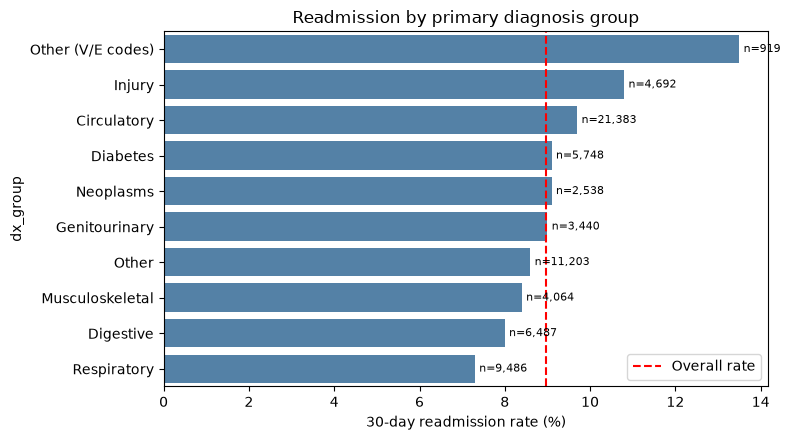

In [110]:
# Step 17.1: Map ICD-9 codes to clinical groups. Codes look like "250.83", "428", "V57", "E909".
def icd9_group(code):
    if pd.isna(code) or code == "Missing":
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):
        return "Other (V/E codes)"
    try:
        k = int(float(c))              # integer part: "250.83" -> 250
    except ValueError:
        return "Other"
    if k == 250:                        return "Diabetes"
    if 390 <= k <= 459 or k == 785:     return "Circulatory"
    if 460 <= k <= 519 or k == 786:     return "Respiratory"
    if 520 <= k <= 579 or k == 787:     return "Digestive"
    if 580 <= k <= 629 or k == 788:     return "Genitourinary"
    if 800 <= k <= 999:                 return "Injury"
    if 710 <= k <= 739:                 return "Musculoskeletal"
    if 140 <= k <= 239:                 return "Neoplasms"
    return "Other"

clean["dx_group"] = clean["diag_1"].map(icd9_group)
dx = rate_by("dx_group").sort_values("rate", ascending=False)
display(dx)

# Chart (groups with at least 300 patients)
d = dx[dx["n"] >= 300]
plt.figure(figsize=(8, 4.5))
sns.barplot(x=d["rate"], y=d.index, color="steelblue")
plt.axvline(baseline, color="red", linestyle="--", label="Overall rate")
for i, (r, n) in enumerate(zip(d["rate"], d["n"])):
    plt.text(r + 0.1, i, f"n={n:,}", va="center", fontsize=8)
plt.xlabel("30-day readmission rate (%)")
plt.title("Readmission by primary diagnosis group")
plt.legend()
plt.tight_layout()
plt.show()

### Observation: Readmission by primary diagnosis group
- Rates are fairly close across large groups (7.3% respiratory to 10.8% injury) versus 9.0% overall,
  so primary diagnosis is a weaker signal than prior admissions or discharge destination.
- Highest: V/E codes (13.5%, n=919; V codes often describe non-acute care such as rehabilitation, so this may overlap
  with discharge destination) and injury/poisoning (10.8%; this range includes surgical and device complications).
- Lowest: respiratory (7.3%, n=9,486).
- Only 8.2% of patients have diabetes as the primary diagnosis; most are admitted for another condition.
- The "Other" group (16% of patients) is too broad and is split in the next step. Group with n=10 is ignored.

## Step 17.2: Refined diagnosis groups and a fair test of their value
The decision uses 5-fold cross-validation on the development set only. The sealed hold-out is not touched.

In [111]:
# Step 17.2a: A finer ICD-9 mapping (split the oversized "Other" group). Still a simplified grouping.
def icd9_group_v2(code):
    if pd.isna(code) or code == "Missing":
        return "Missing"
    c = str(code)
    if c.startswith("V"):
        return "V codes (non-acute care)"
    if c.startswith("E"):
        return "E codes (external causes)"
    try:
        k = int(float(c))
    except ValueError:
        return "Other"
    if k == 250:                         return "Diabetes"
    if 240 <= k <= 279:                  return "Endocrine/metabolic (non-diabetes)"
    if 390 <= k <= 459 or k == 785:      return "Circulatory"
    if 460 <= k <= 519 or k == 786:      return "Respiratory"
    if 520 <= k <= 579 or k == 787:      return "Digestive"
    if 580 <= k <= 629 or k == 788:      return "Genitourinary"
    if 710 <= k <= 739:                  return "Musculoskeletal"
    if 800 <= k <= 999:                  return "Injury/poisoning"
    if 140 <= k <= 239:                  return "Neoplasms"
    if 1 <= k <= 139:                    return "Infectious"
    if 290 <= k <= 389:                  return "Mental/nervous"
    if 680 <= k <= 709:                  return "Skin"
    if 780 <= k <= 799:                  return "Symptoms/signs"
    return "Other"

clean["dx_group2"] = clean["diag_1"].map(icd9_group_v2)
dx2 = rate_by("dx_group2").sort_values("n", ascending=False)
display(dx2)

,rate,n
dx_group2,,
Circulatory,9.7,21383
Respiratory,7.3,9486
Digestive,8.0,6487
Diabetes,9.1,5748
Injury/poisoning,10.8,4692
Musculoskeletal,8.4,4064
Genitourinary,9.0,3440
Neoplasms,9.1,2538
Mental/nervous,9.7,2403


In [112]:
# Step 17.2b: Does adding the diagnosis group improve the model? Same folds, same model (unweighted logistic regression).
# Uses X_dev / y_dev / cv from Step 12.1. The hold-out is not used here.
dx_all = cohort_a["diag_1"].map(icd9_group_v2)

def cv_scores(X_in):
    num_ = X_in.select_dtypes(include="number").columns.tolist()
    cat_ = X_in.select_dtypes(exclude="number").columns.tolist()
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), num_),
                                    ("cat", make_encoder(), cat_)])),
        ("m", LogisticRegression(max_iter=1000)),
    ])
    return cross_validate(pipe, X_in, y_dev, cv=cv,
                          scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})

X_dev_dx = X_dev.copy()
X_dev_dx["dx_group"] = dx_all.loc[X_dev.index]

base_s = cv_scores(X_dev)
dx_s = cv_scores(X_dev_dx)

for metric in ["roc_auc", "pr_auc"]:
    a, b = base_s[f"test_{metric}"], dx_s[f"test_{metric}"]
    diff = b - a                                   # paired: same fold, with minus without
    print(f"{metric:8s} without dx: {a.mean():.4f} | with dx: {b.mean():.4f} | "
          f"paired diff: {diff.mean():+.4f} +/- {diff.std():.4f} (per-fold SD, 5 folds)")

roc_auc  without dx: 0.6428 | with dx: 0.6449 | paired diff: +0.0021 +/- 0.0022 (per-fold SD, 5 folds)
pr_auc   without dx: 0.1620 | with dx: 0.1618 | paired diff: -0.0002 +/- 0.0012 (per-fold SD, 5 folds)


### Observation: Refined diagnosis groups
- Splitting the oversized "Other" group (11,203 patients) reduced it to 1,278 patients. Rates across large groups stay in a
  narrow band (respiratory 7.3% to injury/poisoning 10.8%, V codes 13.5% with n=918) around 9.0% overall.
- Groups with n < 30 (Missing n=10, E codes n=1) are ignored.

### Observation: Does the diagnosis group improve the model?
- Paired 5-fold cross-validation on the development set (hold-out untouched), logistic regression with and without the group:
  ROC-AUC 0.6428 -> 0.6449 (paired diff +0.0021 +/- 0.0022); PR-AUC 0.1620 -> 0.1618 (diff -0.0002 +/- 0.0012).
- The gain is below the noise threshold set in advance (2x the per-fold SD), so the diagnosis group is NOT added to the final model.
  Its information is probably already captured by discharge destination, number of diagnoses and specialty (not tested).

## Step 18: Medication intelligence v2
(1) A1C and glucose testing, (2) testing together with medication change, (3) regimen type.
Medication drug columns track 10 drugs only; combination pills and other agents are not captured.

In [113]:
# Step 18.1: HbA1c and serum glucose testing ("Not tested" = the test was not done during the stay)
print("HbA1c result:")
display(rate_by("A1Cresult"))
print("Max serum glucose:")
display(rate_by("max_glu_serum"))

HbA1c result:


,rate,n
A1Cresult,,
>7,8.6,2865
>8,8.2,6239
Norm,8.6,3741
Not tested,9.1,57125


Max serum glucose:


,rate,n
max_glu_serum,,
>200,10.9,936
>300,10.1,712
Norm,9.8,1700
Not tested,8.9,66622


In [114]:
# Step 18.2: Was HbA1c tested, and was the diabetes medication changed? (4 combinations)
clean["a1c_tested"] = (clean["A1Cresult"] != "Not tested").astype(int)
t = (clean.groupby(["a1c_tested", "change"])["readmit_30"]
          .agg(rate="mean", n="size"))
t["rate"] = (t["rate"] * 100).round(1)
display(t)

rate      n
a1c_tested change             
0          Ch       9.7  24408
           No       8.7  32717
1          Ch       8.6   7081
           No       8.1   5764

In [115]:
# Step 18.3: Regimen type from the 10 tracked drugs
oral = [c for c in drug_cols if c != "insulin"]
on_insulin = clean["insulin"] != "No"
on_oral = (clean[oral] != "No").any(axis=1)
clean["regimen"] = np.select(
    [on_insulin & on_oral, on_insulin, on_oral],
    ["Insulin + oral", "Insulin only", "Oral only"],
    default="None of the 10 tracked drugs")
display(rate_by("regimen"))

# Check: some patients "without a tracked drug" may be on untracked drugs (diabetesMed flag)
print(pd.crosstab(clean["regimen"], clean["diabetesMed"]))

,rate,n
regimen,,
Insulin + oral,9.4,16186
Insulin only,9.8,19529
None of the 10 tracked drugs,7.6,16909
Oral only,9.0,17346


diabetesMed                      No    Yes
regimen                                   
Insulin + oral                    0  16186
Insulin only                      0  19529
None of the 10 tracked drugs  16679    230
Oral only                         0  17346


In [116]:
# Step 18.4: Same paired CV test as Step 17.2b (hold-out untouched)
X_dev_reg = X_dev.copy()
X_dev_reg["regimen"] = clean["regimen"].loc[X_dev.index]
reg_s = cv_scores(X_dev_reg)

for metric in ["roc_auc", "pr_auc"]:
    a, b = base_s[f"test_{metric}"], reg_s[f"test_{metric}"]
    diff = b - a
    print(f"{metric:8s} without regimen: {a.mean():.4f} | with: {b.mean():.4f} | "
          f"paired diff: {diff.mean():+.4f} +/- {diff.std():.4f}")

roc_auc  without regimen: 0.6428 | with: 0.6424 | paired diff: -0.0003 +/- 0.0002
pr_auc   without regimen: 0.1620 | with: 0.1619 | paired diff: -0.0001 +/- 0.0001


## Step 18: Medication intelligence v2

### Observation: HbA1c and glucose testing
- HbA1c was measured in 18.4% of stays (n=12,845). Tested patients had a lower readmission rate than untested (8.4% vs 9.1%;
  margin of error about +/-0.5 points for the tested group). Among tested patients the result level shows no clear gradient (8.2-8.6%).
- Serum glucose was measured in only 4.8% of stays (n=3,348), with a higher rate (10.2% vs 8.9%), probably because testing is
  triggered by a sicker clinical picture.
- Within each medication-change status, HbA1c-tested patients had lower rates (change: 8.6% vs 9.7%; no change: 8.1% vs 8.7%);
  the second gap is within noise. A medication change was associated with higher rates in both groups.
- These are associations: testing is a marker of how the stay was managed and of patient selection, not proof of an effect.

### Observation: Treatment regimen (10 tracked drugs)
- No tracked drug 7.6% (n=16,909; 98.6% of them have diabetesMed = No), oral only 9.0%, insulin + oral 9.4%, insulin only 9.8%.
- Adding the regimen to the model does not help (paired cross-validation: ROC-AUC -0.0003 +/- 0.0002, PR-AUC -0.0001 +/- 0.0001),
  so it is not added. Insulin use likely marks more severe diabetes; the pattern is not causal.
- The 10 tracked drugs exclude combination pills and other agents; 230 patients with a diabetes-medication flag use none of them.